---
---

<h1><center><ins>Exercise Sheet 3</ins></center></h1>
<h2><center>Numerical Methods <br><br>

---
---

In [238]:
import numpy as np
import matplotlib.pyplot as plt
from numpy import exp

## Exercise 1 - Root finding algorithms

**(A)** Implement the *bisection*, *secant*, *false position* and *Newton-Raphson* root finding methods, by coding your own version of these algorithms. Make sure to test your codes, checking that indeed they are able to find the root of a function (to do this, you can for example pick an analytic function that allows you to test the codes and for which you can compute the roots analytically).

**(B)** Use your implementation of the 4 root finding methods (from part **A**) to compute the root of the function:

$$f(x) = e^x - 1 - x - \frac{x^2}{2}$$

in the interval $x\in[-1,2]$. For each method, print out the position of the root and the number of iterations needed to reach it.

**(C)** Discuss your results, commenting how the methods compare to one another. Which one is the fastest/slowest? Why? What is the impact of the points you selected to start your iterations?

<function matplotlib.pyplot.show(close=None, block=None)>

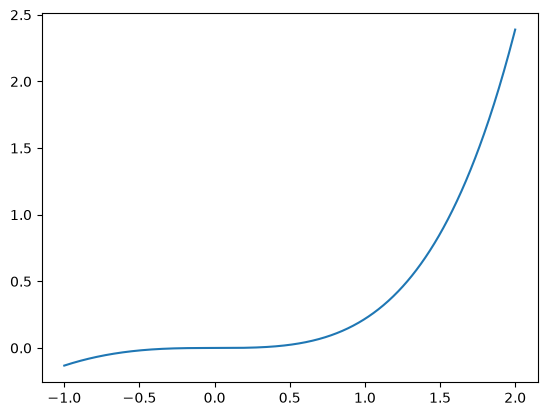

In [239]:
# Bisection

def function(x):
    return (np.exp(x)) - 1 - x - ((x**2)/2)

boundary_1 = -1
boundary_2 = 2

x_achse = np.linspace(-1,2,1000) # x Achse basteln 
y_achse = function(x_achse) # x Achse in Funktion rein 

plt.plot(x_achse, y_achse) 
plt.show # just to visualize

In [240]:
import numpy as np
import matplotlib.pyplot as plt
from numpy import exp

epsilon = 1/10000

def func(x):
    return x**7 + 2*x

def bisection(func,a,b):
    if func(a)*func(b) >= 0:
        return None 
    
    count = 0   

    while True: 
        # while True loop never ends on its own, only when something inside exits (return statement)
        x_m = (a+b)/2 
        count += 1

        # print(a, b, x_m, func(x_m)) 

        if func(x_m) == 0 or (b - a)/2 < epsilon:
            return f'The root is {x_m} and it took {count} iterations to find it.'
        
        elif func(x_m)*func(a) < 0:
            # root is in new interval [a, x_m] 
            b = x_m

        elif func(x_m)*func(b) < 0:
            # root is in new interval [x_m, b]
            a = x_m

      
print(f'bisection method: {bisection(func, -10, 3)}')        
    
print(f'bisection method of f(x): {bisection(function, boundary_1, boundary_2)}')

bisection method: The root is 3.814697265625e-05 and it took 17 iterations to find it.
bisection method of f(x): The root is 3.0517578125e-05 and it took 15 iterations to find it.


In [241]:
# Secant 

def secant(func, a, b):
    if func(a)*func(b) >= 0:
        return None
    
    count = 0 

    while True: 
        x_r = b - (func(b)/(func(b)-func(a)))*(b-a)
        count += 1 

        if np.abs(a-b) < epsilon:
            return f'the root is {x_r} and it took {count} iterations to find it.'

        b = a 
        a = x_r

print(f'secant method: {secant(func, -1, 3)}')

print(f'secant method of f(x): {secant(function, boundary_1, boundary_2)}')

secant method: the root is -6.776263578034403e-21 and it took 7 iterations to find it.
secant method of f(x): the root is -0.0002112135488494475 and it took 30 iterations to find it.


In [242]:
# False position
# Wikipedia 

def false_position(func, a, b):
    if func(a)*func(b) >= 0:
        return None

    c_old = None
    count = 0

    while True:
        c = (a * func(b) - b * func(a))/(func(b) - func(a))
        count += 1

        if func(c) == 0 or (c_old is not None and abs(c - c_old) < epsilon):
            return f'the root is {c} and it took {count} iterations to find it.' 

        elif func(c) * func(a) < 0:
            b = c # use x_1 and x_3 to find x_4

        else:
            a = c # use x_2 and x_3 to find x_4
    
        c_old = c
        # print(a, b, c, func(c))

print(f'false position method: {false_position(func, -1, 3)}')

print(f'false position method of f(x): {false_position(function, boundary_1, boundary_2)}')

false position method: the root is -0.03591913319582871 and it took 1094 iterations to find it.
false position method of f(x): the root is -0.0887073278284555 and it took 432 iterations to find it.


In [243]:
# Newton-Raphson 
# schnellste , aber hier bei HÜ gleich schnell wie bisection 

# Wir brauchen Funktion, inital wert auf x achse , Ableitung der funktion 
# ABleitung händisch tippen 

def function_derivative(x):
    return exp(x) - 1 - x

def newton_raphson(func, dfunc, x0, max_iter=1000):

    x = x0
    count = 0 

    while count < max_iter:
        if dfunc(x) == 0: 
            # slope is 0
            return None 

        delta = -func(x) / dfunc(x)

        if abs(delta) < epsilon:
            return f'The root is {x + delta} and it took {count} iterations to find it.'

        x = x + delta # next guess
        count += 1

    return None # if divergent
        
print(f'Newton-Raphson method of f(x): {newton_raphson(function, function_derivative, 1)}')

Newton-Raphson method of f(x): The root is 0.00015298081707735338 and it took 21 iterations to find it.


Newton Raphson ist generell die schnellste Methode, hier aber bei unserer Aufgabe sollte sie eigentlich so schnell sein wie Bisection. Bei mir dauert die Bisection Methode jedoch 0.4 Sekunden, während die Newton-Raphson Methode 0.0 Sekunden braucht. 

## Exercise 2 - Sets of linear equations

Determine the solution to the following set of linear equations:

$$ 
\begin{cases}
5 x_1 + 3 x_2 &= 15 \\
x_1 - 4 x_2 &= -2 \ ,
\end{cases}
$$

where $x_1$ and $x_2$ are the variables of interest.

**(A)** Formulate the problem by using the matrix representation, as we saw in class, clearly defining the coefficient matrix and the vector of right-hand-side values.

**(B)** Using the appropriate built-in python functions, carry out the LU decomposition of the coefficient matrix, and print out the L and U matrices separately. Solve the set of equations and check that the solution is indeed valid.

**(C)** What is the solution to the following set of equations? 

$$ 
\begin{cases}
x_1 - 4 x_2 &= 3 \\
5 x_1 + 3 x_2 &= -7
\end{cases}
$$

Print out the solution, and motivate the steps you took to solve it.

In [244]:
import scipy

A = np.array([[5, 3],
             [1, -4]], dtype = float) # so we have decimal numbers
b = np.array([15, 2], dtype = float)

lu, piv = scipy.linalg.lu_factor(A) # piv ... pivot, records all the swaps of rows

U = np.triu(lu) # triu keeps the upper triangle and sets everything below to 0 
L = np.tril(lu, -1) + np.eye(2) # tril to get the lower triangular matrix, -1 means to start one diagonal below the main one 
                                # np.eye(2) is the identity matrix of a 2x2 matrix, we add it so there aren't zeros on the diagonal

print('Upper triangular matrix:', U)
print('Lower triangular matrix', L)

x = scipy.linalg.lu_solve((lu, piv), b)
print('x:', x)

print(A @ x, '=', b)
print(np.allclose(A @ x, b)) # allclose for decimal rounding, so that even if there is a small deviation due to rounding, it still returns the right result
print(np.allclose(L @ U, A))


Upper triangular matrix: [[ 5.   3. ]
 [ 0.  -4.6]]
Lower triangular matrix [[1.  0. ]
 [0.2 1. ]]
x: [2.86956522 0.2173913 ]
[15.  2.] = [15.  2.]
True
True


In [245]:
b_2 = np.array([-7, 3], dtype = float)
x_2 = scipy.linalg.lu_solve((lu, piv), b_2)
print('x:', x)
print(np.allclose(A @ x_2, b_2))

x: [2.86956522 0.2173913 ]
True


## Exercise 3 - The Newton fractal

In the lecture, we discussed the Newton fractal. The aim of this exercise is to plot it. 

**(A)** Generate a complex plane of numbers between [-2,2] for the real and imaginary parts. You can use the function np.linspace for the Re and Im parts (assume a sufficient number of points, for instance, a few hundred), and then use np.meshgrid to create a full Re, Im grid. You create the complex numbers by using Z = X + 1j * Y. This is the initial set of complex points for your iteration.

**(B)** For every starting point in your grid that you generated in (A), run the Newton-Raphson iteration as $$z_{i+1} = z_{i} - \frac{z_{i}^3 - 1}{3 z_{n}^2} $$ Test how many times you need to run the iteration for the values to converge to one of the three roots (tip: several tens of iteration should be sufficient).

**(C)** Calculate analytically or look up online the three roots of the function $$f(z) = z^3 - 1$$ and store them. For each point you have obtained in (B), calculate the distance to every root using, for instance, np.abs. and determine the nearest root. 

**(D)** Plot the result. You can use the function plt.imshow or a similar solution. Assign the color to each plot according to the nearest root. Add the three roots using e.g. plt.scatter.

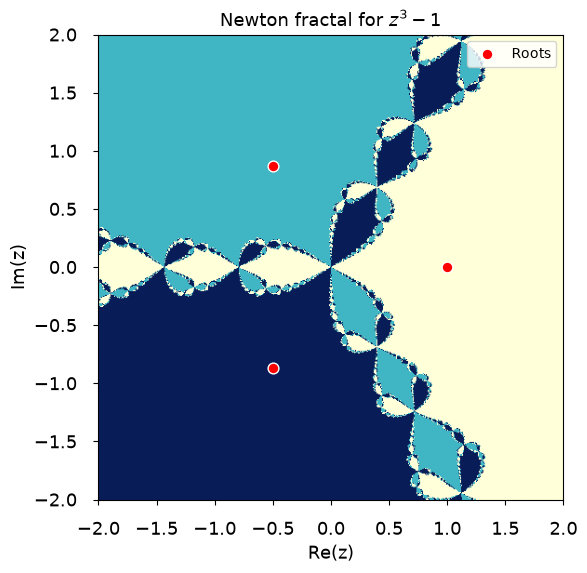

In [ ]:
n = 500
re = np.linspace(-2, 2, n) # real axis
im = np.linspace(-2, 2, n) # imaginary 
X, Y = np.meshgrid(re, im) # both together 
Z = X + 1j * Y # j is the imaginary number i

for i in range(50):
    Z = Z - (Z**3 - 1) / (3 * Z**2)

roots = np.array([1,
                  -0.5 + 1j * np.sqrt(3) / 2,
                  -0.5 - 1j * np.sqrt(3) / 2])
    # the three roots

d_0 = np.abs(Z - roots[0]) # distance of every point to every root
d_1 = np.abs(Z - roots[1])
d_2 = np.abs(Z - roots[2])

nearest = np.argmin([d_0, d_1, d_2], axis=0) # argmin for identifiying the index of the first occurrence of the minimum value in an array; index (0, 1 or 2) of the nearest root for every point

plt.figure(figsize=(6, 7))
plt.imshow(nearest, extent=[-2, 2, -2, 2], origin='lower', cmap='YlGnBu')
plt.scatter(roots.real, roots.imag, color='red', edgecolor='white', s=60, label='Roots')

plt.tick_params(axis='x', which='major', labelsize=13, pad=12, colors='black')
plt.tick_params(axis='y', which='major', labelsize=13, pad=12, colors='black')
plt.title('Newton fractal for $z^3 - 1$', size=13)
plt.xlabel('Re(z)', size=13)
plt.ylabel('Im(z)', size=13)
plt.legend()

#plt.savefig("Newton fractal.pdf")
plt.show()